# Figure 3 — Heat-responsive allelic regulation: overview, motifs, and a peptidase case study

Panels:
- **A.** Volcano plot of allele-level DE genes (heat vs. control, voom/limma on batch-corrected counts)
- **B.** Genome-wide overview of pairwise allelic log2FC divergence under heat (EM-based transcript counts), split into no-change / allele_i-higher / allele_j-higher
- **C.** Enriched promoter motifs — gene filtering for the MEME differential-enrichment analysis, and the discovered motifs
- **D.** Case-study gene: haplotype-resolved CPM in control vs. heat (EM-based transcript counts), marking which pairwise haplotype comparisons are significant
- **E.** Luciferase reporter assay results (wet-lab validation)
- **F.** Promoter alignment for a heat-responsive peptidase gene (Soltu.DM.08G022800) showing a haplotype with no measurable heat response next to one that is strongly induced



Inputs: `clean_data/Fig3_heat_responsive_alleles/`

In [1]:
library(dplyr)
library(stringr)
library(readr)
library(ggplot2)
library(EnhancedVolcano)
library(seqinr)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: ggrepel


Attaching package: ‘seqinr’


The following object is masked from ‘package:dplyr’:

    count




## Setup

In [2]:
DATA_DIR <- "../clean_data/Fig3_heat_responsive_alleles"
OUT_DIR  <- "./figures/Fig3"
dir.create(OUT_DIR, showWarnings = FALSE, recursive = TRUE)


## Load DE results

`voom_results_desiree_liftoff_phased.tsv` is the batch-corrected, allele-level voom/limma
DE table (heat vs. control), already merged with average CPM per condition
(`avg_heat`, `avg_control`) and functional annotation (`functional_annotation`).

In [3]:
merged_data <- read_tsv(file.path(DATA_DIR, "voom_results_desiree_liftoff_phased.tsv"),
                         quote = "", show_col_types = FALSE)

# one row per haplotype-resolved transcript/gene
res <- as.data.frame(merged_data)
rownames(res) <- res$original_index


## Panel A — Volcano plot (heat vs. control)

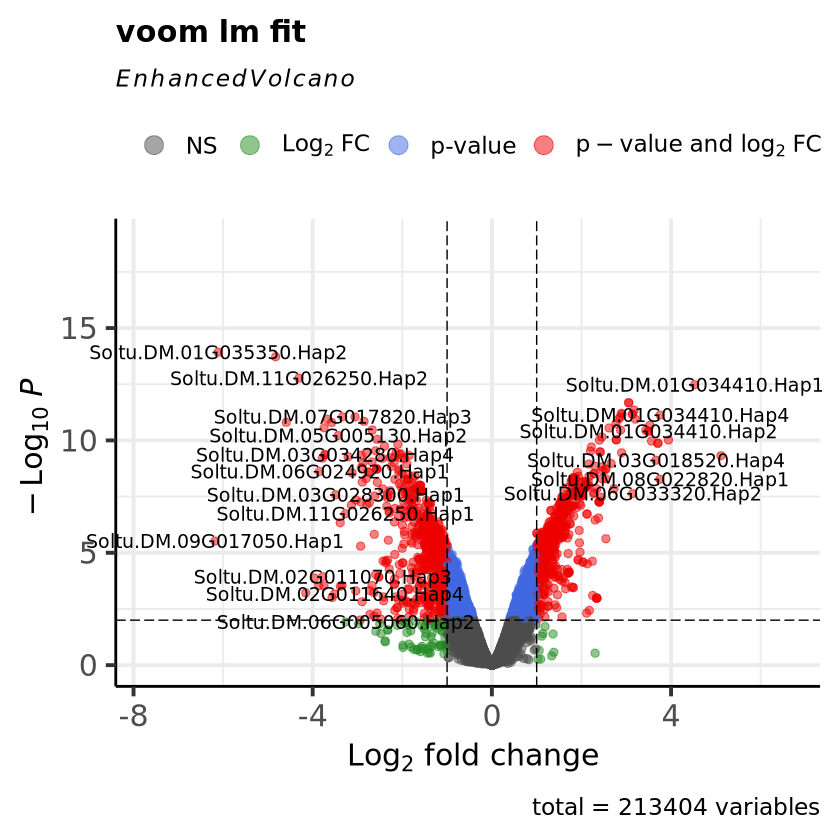

In [4]:
# guard against NA: merged_data includes genes that never passed the expression
# filter (NA logFC/P.Value), and base R's `x[condition]` keeps an NA row for every NA
# in `condition` instead of dropping it
genes_to_label <- rownames(res)[!is.na(res$logFC) & abs(res$logFC) > 3]

p_volcano <- EnhancedVolcano(res,
  lab = rownames(res),
  x = "logFC",
  y = "P.Value",
  pCutoff = 0.01,
  FCcutoff = 1,
  title = "voom lm fit",
  selectLab = genes_to_label,
  colConnectors = "black",
  labSize = 4)

p_volcano
ggsave(file.path(OUT_DIR, "Fig3A_volcano_plot.svg"), p_volcano, width = 6, height = 7)


## Panel B — Overview: genome-wide allelic log2FC divergence under heat

For every haplotype pair in `trans_pairwise_results_em_counts.tsv` with CPM > 1 in
heat for both alleles, this compares each allele's own heat-vs-control log2FC side
by side, split into three groups by how much the pair's induction diverges
(`diff = log2FC_j - log2FC_i`): not meaningfully different (`|diff| < 1`), allele_j
more induced, or allele_i more induced.

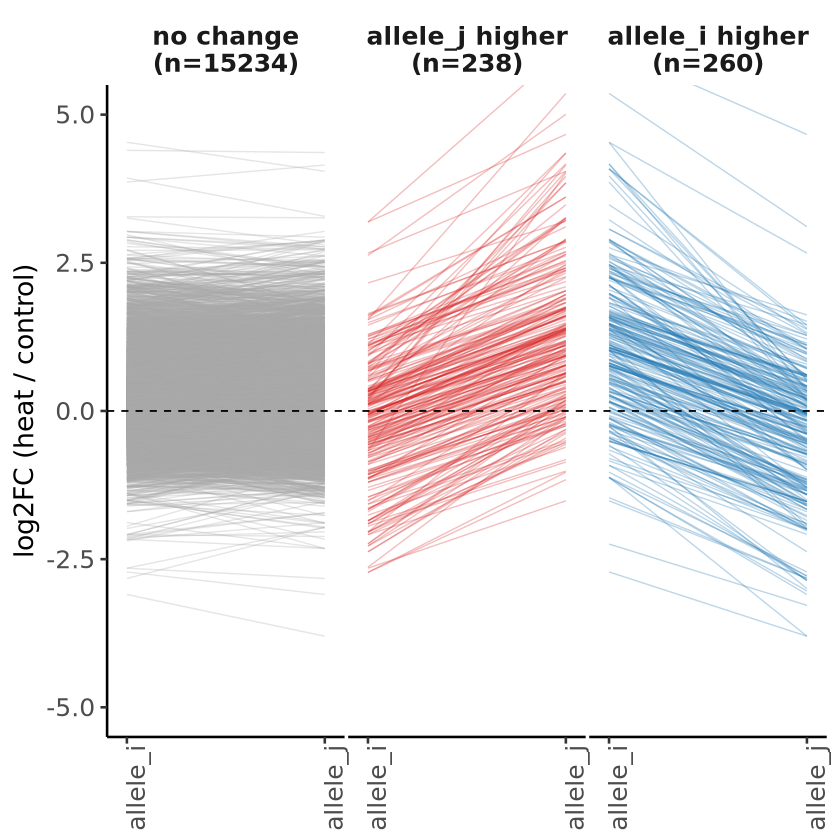

In [5]:
pairwise_trans_results <- read_tsv(file.path(DATA_DIR, "trans_pairwise_results_em_counts.tsv"),
                                     show_col_types = FALSE)

# Restrict to pairs where both alleles are actually expressed under heat, then split
# by how much the two alleles' heat-vs-control log2FC diverge from each other.
divergence_cut <- 1

pairwise_trans_overview <- pairwise_trans_results %>%
  filter(cpm_i_heat_mean > 1, cpm_j_heat_mean > 1) %>%
  mutate(
    pair_id  = row_number(),
    diff     = log2FC_j - log2FC_i,
    category = case_when(
      abs(diff) < divergence_cut ~ "no change",
      diff > 0                   ~ "allele_j higher",
      TRUE                        ~ "allele_i higher"
    ),
    category = factor(category, levels = c("no change", "allele_j higher", "allele_i higher"))
  )

category_colors <- c("no change" = "#aaaaaa", "allele_j higher" = "#d62728", "allele_i higher" = "#1f77b4")

# seqinr::count() masks dplyr::count() (see the library-load warnings above), so
# this needs the explicit dplyr:: prefix.
facet_n <- dplyr::count(pairwise_trans_overview, category)
facet_labels <- setNames(paste0(facet_n$category, "\n(n=", facet_n$n, ")"), facet_n$category)

# Long format (one row per pair per allele side) so each pair can be drawn as a
# single line segment from allele_i to allele_j.
slope_df <- bind_rows(
  pairwise_trans_overview %>% transmute(pair_id, category, allele = "allele_i", log2FC = log2FC_i),
  pairwise_trans_overview %>% transmute(pair_id, category, allele = "allele_j", log2FC = log2FC_j)
) %>%
  mutate(allele = factor(allele, levels = c("allele_i", "allele_j")))

p_slopegraph <- ggplot(slope_df, aes(x = allele, y = log2FC, group = pair_id, color = category)) +
  geom_line(alpha = 0.3, linewidth = 0.4) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "black") +
  scale_color_manual(values = category_colors) +
  scale_x_discrete(expand = expansion(add = 0.1)) +
  facet_wrap(~category, nrow = 1, labeller = as_labeller(facet_labels)) +
  coord_cartesian(ylim = c(-5, 5)) +
  labs(x = NULL, y = "log2FC (heat / control)") +
  theme_classic(base_size = 16) +
  theme(
    legend.position = "none",
    panel.spacing = unit(0.15, "lines"),
    strip.background = element_blank(),
    strip.text = element_text(size = 15, face = "bold"),
    axis.text.x = element_text(size = 15, ,angle = 90),
    axis.text.y = element_text(size = 15),
    axis.title.y = element_text(size = 16),
  )

p_slopegraph
ggsave(file.path(OUT_DIR, "Fig3B_pairwise_trans_slopegraph_overview.svg"), p_slopegraph, width = 8, height = 3)


## Panel C — Enriched promoter motifs

### Filtering the genes used for the motif-enrichment analysis

MEME (Differential Enrichment mode) was run with two haplotype-level gene sets:
- **primary set**: heat-upregulated (`logFC > 2` and `P.Value < 0.01`)
- **background set**: not heat-responsive (`-0.1 < logFC < 0.1`), i.e. the genes MEME
  looks for the primary set's motifs being enriched *against*

These thresholds are the ones actually used to build the primary/background promoter
FASTA files submitted to MEME (recovered from the saved gene-list files, since the
source notebook's inline comments didn't match what was actually run).

In [6]:
heat_upregulated_cut <- 2
heat_upregulated_pcut <- 0.01
not_changing_cut <- 0.1

# dplyr::filter() drops NA rows automatically (base R's `x[condition, ]` would instead
# keep an all-NA row for every NA in `condition` -- merged_data has ~213k rows for
# genes that never passed the expression filter and so have NA logFC/P.Value)
heat_upregulated <- merged_data %>% filter(logFC > heat_upregulated_cut, P.Value < heat_upregulated_pcut)
not_changing      <- merged_data %>% filter(logFC > -not_changing_cut, logFC < not_changing_cut)

cat("heat-upregulated (logFC >", heat_upregulated_cut, "& P.Value <", heat_upregulated_pcut, "):",
    nrow(heat_upregulated), "haplotype-level entries\n")
cat("not-changing background (|logFC| <", not_changing_cut, "):",
    nrow(not_changing), "haplotype-level entries\n")

write.table(heat_upregulated$original_index, file.path(OUT_DIR, "heat_upregulated_gene_ids.txt"),
            quote = FALSE, row.names = FALSE, col.names = FALSE)
write.table(not_changing$original_index, file.path(OUT_DIR, "background_notchanging_gene_ids.txt"),
            quote = FALSE, row.names = FALSE, col.names = FALSE)


heat-upregulated (logFC > 2 & P.Value < 0.01 ): 88 haplotype-level entries
not-changing background (|logFC| < 0.1 ): 6729 haplotype-level entries


### Promoter extraction & MEME run (external; not re-executed here)

The two gene-id lists above were used to pull each gene's 2000bp-upstream promoter
sequence from the genome-wide promoter FASTA, then submitted to
[MEME](https://meme-suite.org/meme/tools/meme) (Differential Enrichment mode, primary
vs. background, "Any Number of Repetitions" site distribution, 5 motifs requested):

```bash
# pull promoter sequences for each gene set (requires the full-genome promoter FASTA
# and transcript-to-gene mapping, not included in clean_data — see the source notebook
# ANALYSIS/notebooks/trans_motiv_enrichment/promotor_extraction_heat_induced_gene_id.sh
# for the exact commands)
seqkit grep -i -f heat_upregulated_gene_ids.txt   desiree_2000_up_down_stream_transcript_ids.fa > desiree_heat_upregulated_2000_promoters.fa
seqkit grep -i -f background_notchanging_gene_ids.txt desiree_2000_up_down_stream_transcript_ids.fa > desiree_heat_downregulated_not_changing_2000_promoters.fa

# submitted to MEME as primary vs. control sequences (Differential Enrichment mode)
```



## Panel F — Promoter alignment: a peptidase with haplotype-specific heat response

`Soltu.DM.08G022800` ("Peptidase M20/M25/M40 family protein") shows a striking
haplotype-specific response to heat: Hap1 (logFC = 2.42, adj.P = 2.3e-7) and Hap4
(logFC = 3.56, adj.P = 9.0e-8) are both strongly heat-induced, while **Hap3 has no DE
statistics at all** — it didn't pass the expression filter, despite comparable average
CPM to the other haplotypes. The alignment below compares the Hap3 and Hap4 promoter
sequences (2000bp upstream + UTR) to look for sequence differences that could explain
why Hap3 fails to respond like Hap4 does.

pdf 
  2

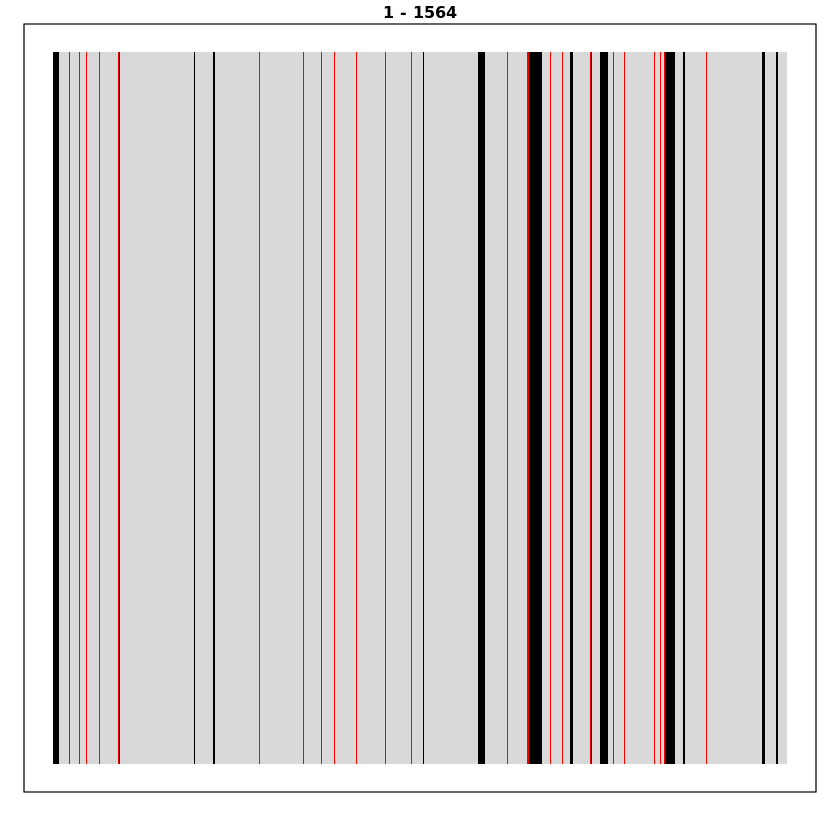

In [7]:
# Compact identity plot for two aligned sequences (Clustal format).
# Shows the whole alignment as `n_rows` stacked horizontal tracks so the plot stays
# narrow. Each position is colored by status: match (light grey), mismatch (red),
# indel/gap (black).
plot_alignment_identity <- function(aln_file, n_rows = 3,
                                     seq_names = NULL,
                                     col_match = "grey85",
                                     col_mismatch = "red",
                                     col_indel = "black") {

  aln <- read.alignment(file = aln_file, format = "clustal")
  if (aln$nb != 2) stop("Expected exactly 2 sequences in the alignment.")

  s1 <- toupper(strsplit(aln$seq[[1]], "")[[1]])
  s2 <- toupper(strsplit(aln$seq[[2]], "")[[1]])
  n  <- length(s1)
  if (length(s2) != n) stop("Aligned sequences have different lengths.")

  # Classify each alignment column
  status <- ifelse(s1 == s2, 0L,                      # match
             ifelse(s1 == "-" | s2 == "-", 2L, 1L))    # indel vs mismatch

  if (is.null(seq_names)) seq_names <- aln$nam

  # Pad so length is divisible by n_rows
  row_len <- ceiling(n / n_rows)
  pad_len <- row_len * n_rows - n
  status_padded <- c(status, rep(NA, pad_len))
  m <- matrix(status_padded, nrow = n_rows, byrow = TRUE)

  cols <- c(col_match, col_mismatch, col_indel)

  par(mfrow = c(n_rows, 1), mar = c(2, 1, 1, 1))

  for (r in seq_len(n_rows)) {
    row_vals <- m[r, ]
    start_pos <- (r - 1) * row_len + 1
    end_pos <- min(r * row_len, n)

    plot(NA, xlim = c(0, row_len), ylim = c(0, 1),
         xlab = "", ylab = "", axes = FALSE,
         main = paste0(start_pos, " - ", end_pos), cex.main = 0.8)

    valid <- !is.na(row_vals)
    x <- which(valid)
    rect(x - 1, 0, x, 1,
         col = cols[row_vals[valid] + 1], border = NA)

    box()
  }

  par(mfrow = c(1, 1))
  legend("bottom", inset = -0.3, xpd = NA, horiz = TRUE,
         legend = c("match", "mismatch", "indel"),
         fill = cols, bty = "n", cex = 0.8)
}

peptidase_aln <- file.path(DATA_DIR, "peptidase_alignment.aln")
par(bg = "white")
svg(file.path(OUT_DIR, "Fig3F_peptidase_promoter_alignment.svg"), width = 6, height = 1)
plot_alignment_identity(peptidase_aln, n_rows = 1, seq_names = c("Hap3", "Hap4"))
dev.off()

# also show it inline
par(bg = "white")
plot_alignment_identity(peptidase_aln, n_rows = 1, seq_names = c("Hap3", "Hap4"))


## Panel D — Example gene: haplotype-specific expression under heat stress

`Soltu.DM.08G022800` (`Synt_id_46611`, "Peptidase M20/M25/M40 family protein") is a
useful case study beyond the promoter alignment above: Hap3 has no DE statistics in
the voom table (Panel E) because it didn't pass the expression filter, despite
comparable average CPM to Hap1/Hap4. The EM-based transcript-level quantification in
`trans_pairwise_results_em_counts.tsv` recovers a signal for Hap3 anyway — all three
haplotypes are significantly heat-induced (FDR < 0.05 for every pairwise comparison),
but to very different degrees: Hap1 (control ≈ 53 CPM → heat ≈ 153, log2FC ≈ 1.5),
Hap3 (≈ 2.6 → 107, log2FC ≈ 5.4) and Hap4 (≈ 45 → 392, log2FC ≈ 3.1).


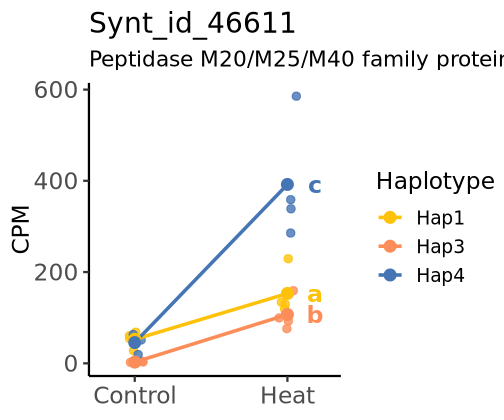

In [8]:
# pairwise_trans_results was already loaded in Panel B above

# Parse the array-string CPM columns (`cpm_rep_*`), which were exported as Python's
# default str(numpy array), e.g. "[1.06 3.15 3.92 2.29]", back into numeric vectors.
parse_cpm_rep <- function(s) {
  as.numeric(unlist(str_extract_all(s, "[-+]?[0-9]*\\.?[0-9]+(?:[eE][-+]?[0-9]+)?")))
}

# Compact-letter display: assign group letters so two haplotypes only share a
# letter if they are NOT significantly different (i.e. not in `sig_pairs`).
compact_letter_display <- function(items, sig_pairs) {
  is_sig <- function(a, b) any(vapply(sig_pairs, function(p) setequal(p, c(a, b)), logical(1)))

  groups <- list()
  for (item in items) {
    added <- FALSE
    for (i in seq_along(groups)) {
      if (all(!vapply(groups[[i]], function(other) is_sig(item, other), logical(1)))) {
        groups[[i]] <- c(groups[[i]], item)
        added <- TRUE
      }
    }
    if (!added) groups[[length(groups) + 1]] <- item
  }

  letters_map <- setNames(rep("", length(items)), as.character(items))
  for (i in seq_along(groups)) {
    letter <- letters[i]
    for (item in groups[[i]]) {
      key <- as.character(item)
      letters_map[key] <- paste0(letters_map[key], letter)
    }
  }
  letters_map
}

# Build a control-vs-heat, per-replicate, per-haplotype CPM plot for one gene (all
# rows sharing the same Synt_id), with a compact-letter-display of which pairwise
# haplotype comparisons are significant: FDR < fdr_threshold AND
# |log2FC_difference| > log2fc_threshold (FDR alone can flag pairs whose
# regulatory divergence, while statistically robust, is too small in magnitude to
# be biologically interesting).
#
# Haplotypes sharing a letter are NOT significant by this joint criterion;
# haplotypes with no shared letter differ significantly in their heat-induced
# log2FC, by both a FDR and an effect-size cutoff.
plot_gene_haplotype_heat_response <- function(gene_id, results_df, fdr_threshold = 0.05,
                                                log2fc_threshold = 1, hap_colors = NULL) {
  gene_rows <- results_df %>% filter(Synt_id == gene_id)
  if (nrow(gene_rows) == 0) stop("No rows found for Synt_id == ", gene_id)

  # Collect per-haplotype replicate CPM, deduplicated across the pairwise rows
  # (each haplotype can appear as either the "i" or "j" side).
  hap_list <- list()
  for (k in seq_len(nrow(gene_rows))) {
    row <- gene_rows[k, ]
    for (side in c("i", "j")) {
      hap <- as.character(row[[paste0("haplotype_", side)]])
      if (is.null(hap_list[[hap]])) {
        hap_list[[hap]] <- list(
          control = parse_cpm_rep(row[[paste0("cpm_rep_", side, "_control")]]),
          heat    = parse_cpm_rep(row[[paste0("cpm_rep_", side, "_heat")]])
        )
      }
    }
  }
  haplotypes <- sort(as.integer(names(hap_list)))

  hap_df <- bind_rows(lapply(haplotypes, function(h) {
    d <- hap_list[[as.character(h)]]
    bind_rows(
      tibble(haplotype = paste0("Hap", h), condition = "Control", cpm = d$control),
      tibble(haplotype = paste0("Hap", h), condition = "Heat", cpm = d$heat)
    )
  })) %>%
    mutate(condition = factor(condition, levels = c("Control", "Heat")))

  hap_means <- hap_df %>% group_by(haplotype, condition) %>%
    summarise(mean_cpm = mean(cpm), .groups = "drop")

  # Significant pairs: FDR AND effect-size gated
  sig_rows <- gene_rows %>%
    filter(FDR < fdr_threshold, abs(log2FC_difference) > log2fc_threshold)
  sig_pairs <- lapply(seq_len(nrow(sig_rows)), function(k) {
    c(sig_rows$haplotype_i[k], sig_rows$haplotype_j[k])
  })
  letters_map <- compact_letter_display(haplotypes, sig_pairs)

  # Stack the significance letters next to the heat-side means so close labels
  # don't overlap
  label_df <- hap_means %>% filter(condition == "Heat") %>% arrange(mean_cpm)
  yrange <- diff(range(hap_df$cpm))
  min_gap <- 0.06 * yrange
  label_y <- numeric(0)
  prev <- NA
  for (i in seq_len(nrow(label_df))) {
    y <- label_df$mean_cpm[i]
    if (!is.na(prev) && (y - prev) < min_gap) y <- prev + min_gap
    label_y <- c(label_y, y)
    prev <- y
  }
  label_df$label_y <- label_y
  label_df$letters <- vapply(label_df$haplotype,
                              function(h) letters_map[[sub("Hap", "", h)]], character(1))

  if (is.null(hap_colors)) {
    # Hap3/Hap4 reuse the exact colors from the Panel F luciferase assay (same
    # gene, same two haplotypes) so the two panels read as one visual system.
    default_pal <- c(Hap1 = "#FFC20A", Hap2 = "#1a9850", Hap3 = "#fc8d59", Hap4 = "#4575b4")
    hap_colors <- default_pal[paste0("Hap", haplotypes)]
  }


  # functional_annotation_i repeats the same string once per aligned isoform --
  # collapse to the unique parts only
  annotation_parts <- unique(str_split(gene_rows$functional_annotation_i[1], "/")[[1]])
  annotation <- paste(annotation_parts, collapse = "/")

  ggplot(hap_df, aes(x = condition, y = cpm, color = haplotype, group = haplotype)) +
    geom_jitter(width = 0.06, size = 2, alpha = 0.8) +
    stat_summary(fun = mean, geom = "line", linewidth = 1) +
    stat_summary(fun = mean, geom = "point", size = 3) +
    geom_text(data = label_df, aes(x = condition, y = label_y, label = letters, color = haplotype),
               nudge_x = 0.18, fontface = "bold", size = 5, show.legend = FALSE) +
    scale_color_manual(values = hap_colors) +
    scale_x_discrete(expand = expansion(mult = c(0.3, 0.35))) +
    labs(x = NULL, y = "CPM", color = "Haplotype", title = gene_id, subtitle = annotation) +
    theme_classic(base_size = 14) +
    theme(
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size = 14),
    strip.text = element_text(size = 14, face = "bold")
  ) +
    theme(
      plot.subtitle = element_text(size = 13),
      panel.grid.minor = element_blank()
    )
}

options(repr.plot.width = 4.2, repr.plot.height = 3.5)
p_hap_response <- plot_gene_haplotype_heat_response("Synt_id_46611", pairwise_trans_results)
p_hap_response
ggsave(file.path(OUT_DIR, "Fig3D_peptidase_haplotype_heat_response.svg"), p_hap_response, width = 4.2, height = 4.2)



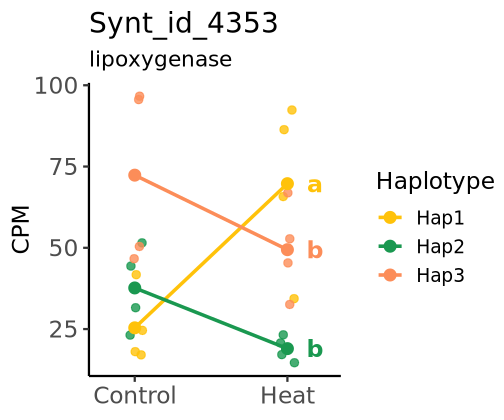

In [9]:
### Lioxygenase

p_hap_response <- plot_gene_haplotype_heat_response("Synt_id_4353", pairwise_trans_results)
p_hap_response
ggsave(file.path(OUT_DIR, "Fig3D_LOX_haplotype_heat_response.svg"), p_hap_response, width = 4.2, height = 4.2)

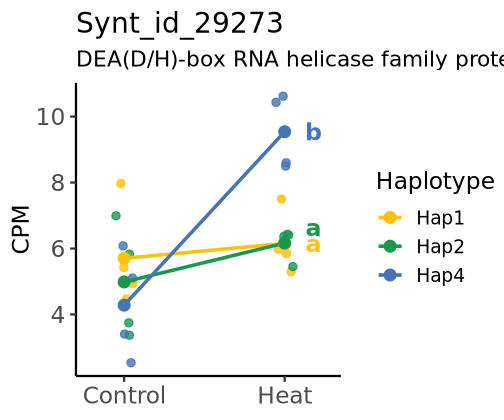

In [10]:
# Dead box 

p_hap_response <- plot_gene_haplotype_heat_response("Synt_id_29273", pairwise_trans_results)
p_hap_response
ggsave(file.path(OUT_DIR, "Fig3D_DEAD_haplotype_heat_response.svg"), p_hap_response, width = 4.2, height = 4.2)

## Panel E — Luciferase reporter assay 

In [76]:
# read in excel from LUC assays -- sheet 1 is the heat treatment, sheet 2 is the
# matched untreated control (same layout, both needed for the combined plot below)
library(readxl)
xlsx_path <- "/scratch/nadjafn/LR_DESIREE_PAPER/clean_data/20260415_Pept_H3_H4_d1_d2_ctrl_heat_edit.xlsx"
luc_assay_heat <- read_excel(xlsx_path, skip = 3, sheet = 1)
luc_assay_ctrl <- read_excel(xlsx_path, skip = 3, sheet = 2)

Warning message:
“Expecting numeric in A1089 / R1089C1: got 'Statistics'”
Warning message:
“Expecting numeric in B1090 / R1090C2: got 'Measurement:'”
Warning message:
“Expecting numeric in B1091 / R1091C2: got '16/04/2026 14:57:14'”
Warning message:
“Expecting numeric in B1093 / R1093C2: got 'Data File:'”
Warning message:
“Expecting numeric in B1094 / R1094C2: got '20260414_Pept_H3_H4_d1_d2.wgd'”
Warning message:
“Expecting numeric in B1096 / R1096C2: got 'Parameter File:'”
Warning message:
“Expecting numeric in B1097 / R1097C2: got 'prom_repeated_plateout_0.5h.wgp'”
Warning message:
“Expecting numeric in B1099 / R1099C2: got 'Reader:'”
Warning message:
“Expecting numeric in B1100 / R1100C2: got 'BertholdTech CENTRO, Driver Version: 2.03 (70325) (2.0.3.0), S/N: 20-1005, Embedded Version: 2.02'”
Warning message:
“Expecting numeric in B1101 / R1101C2: got 'Plate Type: Berthold 96 - No:23300/23302'”
Warning message:
“Expecting numeric in B1102 / R1102C2: got 'Name .....................  D

In [80]:
# The raw plate-reader export is a full 96-well grid (columns A1..H12) plus a block
# of derived per-timepoint summary columns at the end. Two of those summary columns
# are themselves named "H3"/"H4" (the promoter-haplotype averages we actually want),
# which collide with wells H3/H4 already in the grid -- read_excel deduplicates by
# suffixing them "H3...99"/"H4...100" (see the "New names" messages above).
extract_luc_summary <- function(df, condition_label) {
  bind_rows(
    tibble(condition = condition_label, time_s = df$`Time [s]`,
           allele = "Hap3", luciferase_activity = df$`H3...99`, stdev = df$`stdev H3`),
    tibble(condition = condition_label, time_s = df$`Time [s]`,
           allele = "Hap4", luciferase_activity = df$`H4...100`, stdev = df$`stdev H4`),
    tibble(condition = condition_label, time_s = df$`Time [s]`,
           allele = "Hap4 short", luciferase_activity = df$`H4 del`, stdev = df$`stdev H4 d1`)
  )
}

luc_assay_long <- bind_rows(
  extract_luc_summary(luc_assay_heat, "heat"),
  extract_luc_summary(luc_assay_ctrl, "control")
) %>%
  # trailing blank rows in the sheet (past the last real timepoint) come through as NA
  filter(!is.na(time_s), !is.na(luciferase_activity)) %>%
  mutate(
    time_hours = time_s / 3600,
    condition  = factor(condition, levels = c("control", "heat"))
  )

# Same Hap3/Hap4 colors as Panel D, so the two panels read as one visual system.
allele_colors <- c(Hap3 = "#484848", Hap4 = "#370fd7", `Hap4 short` = "#a79cd4")


In [81]:
# Normalize per condition, scaled *10 larger (0–10 range instead of 0–1)
luc_assay_long <- luc_assay_long %>%
  group_by(condition) %>%
  mutate(max_luc = max(luciferase_activity, na.rm = TRUE),
         luciferase_activity = luciferase_activity / max_luc * 10,
         stdev = stdev / max_luc * 10) %>%
  ungroup()

# Scaling factor label per condition (built before max_luc is dropped)
scale_labels <- luc_assay_long %>%
  distinct(condition, max_luc) %>%
  mutate(label = paste0("x", signif(max_luc, 3)))

luc_assay_long <- luc_assay_long %>% select(-max_luc)

limit_df <- data.frame(
  condition = "Control",
  time_hours = range(luc_assay_long$time_hours),
  luciferase_activity = c(0, 300000)  # adjust upper limit as needed
)

p_luciferase <- ggplot(luc_assay_long, aes(x = time_hours, y = luciferase_activity, color = allele, fill = allele)) +
  geom_ribbon(aes(ymin = luciferase_activity - stdev, ymax = luciferase_activity + stdev), alpha = 0.3, color = NA) +
  geom_line(linewidth = 1) +
#geom_blank(data = limit_df, aes(x = time_hours, y = luciferase_activity), inherit.aes = FALSE) +
  geom_text(data = scale_labels, aes(x = -Inf, y = Inf, label = label),
            inherit.aes = FALSE, hjust = -0.1, vjust = 1.5, size = 4) +
  scale_color_manual(values = allele_colors) +
  scale_fill_manual(values = allele_colors) +
  facet_wrap(~condition) +
  labs(x = "Time (hours)", y = "Luminescence (RLU)", color = "Promoter", fill = "Promoter") +
  theme_classic(base_size = 14) +
  theme(
axis.text.x = element_text(size = 14),
axis.text.y = element_text(size = 14),
strip.text = element_text(size = 14, face = "bold")
  ) +
  theme(
legend.position = "right",
legend.key.size = unit(1, "cm"),
panel.grid.minor = element_blank(),
strip.background = element_blank(),
strip.text = element_text(face = "bold")
  )

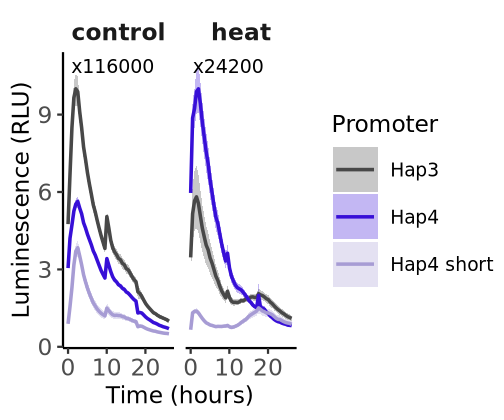

In [82]:

p_luciferase
# save as svg
ggsave(file.path(OUT_DIR, "Fig3E_luciferase_activity_over_time.svg"), p_luciferase, width = 8.5, height = 3.3)
